In [1]:
import folium
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
from os.path import join
import branca.colormap as cm
from folium.plugins import TimeSliderChoropleth

In [2]:
data_path = ""
path_zips = "/glade/work/cbecker/california_zip.geojson"

In [3]:
df = pd.read_parquet(data_path, engine='pyarrow')
dt_idx = df.index.levels[0].astype("int64") // 10 ** 9
df.index = df.index.set_levels(dt_idx.astype("U10"), level=0)
df = df.swaplevel(0, 1)
df

uncorrelated_entropy  radius_of_gyration  \
zipcode date       metric                                             
00012   1710460800 mean                3.906891            2.615795   
                   median              3.906891            2.615795   
                   sum                 3.906891            2.615795   
00017   1710460800 mean                3.596657           15.871472   
                   median              3.321928            1.199382   
...                                         ...                 ...   
96161   1714435200 median              1.921928            0.002995   
                   sum              9002.172178        31169.598184   
96162   1714435200 mean                1.194988            0.102707   
                   median              1.000000            0.001355   
                   sum                 3.584963            0.308121   

                           distance_straight_line  
zipcode date       metric                          
00012   1710460800 mean                  8.055003  
                   median                8.055003  
                   sum                   8.055003  
00017   1710460800 mean                 51.297896  
                   median                2.777127  
...                                           ...  
96161   1714435200 median                0.016345  
                   sum              175728.532537  
96162   1714435200 mean                  0.220988  
                   median                0.002628  
                   sum                   0.662965  

[235452 rows x 3 columns]

In [4]:
gdf_zips = gpd.read_file(path_zips)
gdf_zips.set_index('ZIP_CODE', inplace=True)
gdf_zips.drop('OBJECTID', axis=1, inplace=True)
gdf_zips

,PO_NAME,STATE,POPULATION,POP_SQMI,SQMI,geometry
ZIP_CODE,,,,,,
00012,Mt Meadows Area,CA,-99,-99.00,30.92,"POLYGON ((-120.84352 40.24962, -120.84360 40.2..."
00016,Sequoia National Forest,CA,-99,-99.00,39.33,"POLYGON ((-118.44021 35.55794, -118.38035 35.5..."
00017,Northeast Fresno County,CA,-99,-99.00,564.38,"POLYGON ((-118.77501 37.46305, -118.77447 37.4..."
00018,Los Padres Ntl Forest,CA,-99,-99.00,90.83,"POLYGON ((-118.81778 34.56244, -118.81779 34.5..."
00019,Lassen Ntl Forest,CA,-99,-99.00,412.59,"POLYGON ((-119.99861 40.77159, -119.99848 40.7..."
...,...,...,...,...,...,...
96146,Olympic Valley,CA,1152,149.42,7.71,"POLYGON ((-120.20156 39.21418, -120.19868 39.2..."
96148,Tahoe Vista,CA,1487,991.33,1.50,"POLYGON ((-120.03947 39.23825, -120.04087 39.2..."
96150,South Lake Tahoe,CA,32999,151.87,217.28,"POLYGON ((-119.94957 38.96422, -119.94310 38.9..."


In [5]:
metric = "mean"
df = df.xs(metric, level="metric")
df

,,uncorrelated_entropy,radius_of_gyration,distance_straight_line
zipcode,date,,,
00012,1710460800,3.906891,2.615795,8.055003
00017,1710460800,3.596657,15.871472,51.297896
00019,1710460800,3.024241,26.552332,79.159818
00020,1710460800,2.362774,0.019557,0.055460
00026,1710460800,2.966388,9.048904,28.896094
...,...,...,...,...
96146,1714435200,2.544951,9.156012,37.650910
96148,1714435200,2.578628,10.549973,43.482304
96150,1714435200,1.914436,6.033696,32.384257


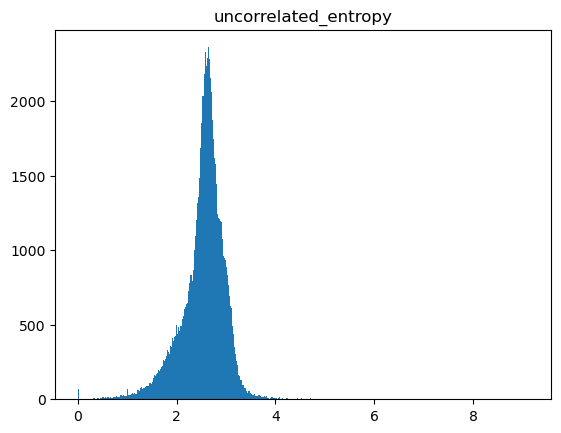

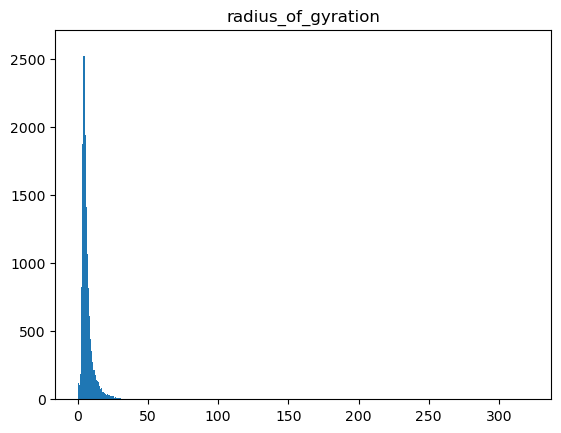

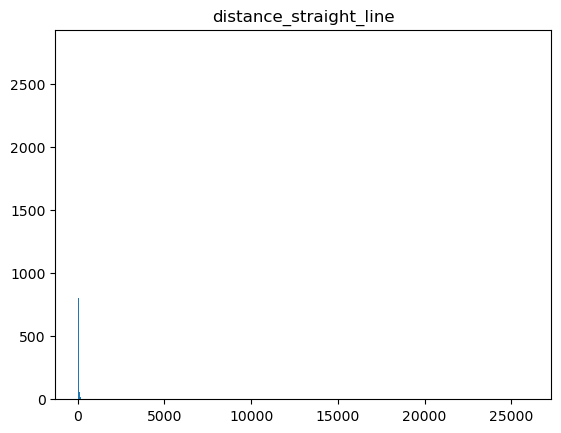

In [6]:
for col in df.columns:
    hist, bins, _ = plt.hist(np.sort(df[col]), bins='fd')
    plt.title(f"{col}")
    plt.show()

In [ ]:
col_idx = 0
col = df.columns[col_idx]
print(col)

min_color = df[col].min().min()
max_color = df[col].max().max()
cmap = cm.linear.PuRd_09.scale(min_color, max_color)
df_style = df[col].to_frame().map(cmap, na_action="ignore").rename(columns={f"{col}": "color"})
df_style = df_style.fillna(0, downcast="int64")
df_style["opacity"] = 0.5

styledict = {}
for zip in df_style.index.levels[0]:
    styledict[zip] = df_style.loc[zip].to_dict(orient="index")

m = folium.Map(location=[34.0549, -118.2426],
               zoom_start=8)

TimeSliderChoropleth(
    gdf_zips.to_json(),
    styledict=styledict,
).add_to(m)

m.save(f"./html/{col}_bydate.html")
m

![title](img/uncorrentropy_byzip_bytime.png)

In [ ]:
col_idx = 1
col = df.columns[col_idx]
print(col)

min_color = df[col].min().min()
max_color = df[col].max().max()
max_color = 25
cmap = cm.linear.PuRd_09.scale(min_color, max_color)
df_style = df[col].to_frame().map(cmap, na_action="ignore").rename(columns={f"{col}": "color"})
df_style = df_style.fillna(0, downcast="int64")
df_style["opacity"] = 0.9

styledict = {}
for zip in df_style.index.levels[0]:
    styledict[zip] = df_style.loc[zip].to_dict(orient="index")

m = folium.Map(location=[34.0549, -118.2426],
               zoom_start=8)

TimeSliderChoropleth(
    gdf_zips.to_json(),
    styledict=styledict,
).add_to(m)

m.save(f"./html/{col}_bydate.html")
m

![title](img/radgyr_byzip_bytime.png)

In [ ]:
col_idx = 2
col = df.columns[col_idx]
print(col)

min_color = df[col].min().min()
max_color = df[col].max().max()
cmap = cm.linear.PuRd_09.scale(min_color, max_color)
df_style = df[col].to_frame().map(cmap, na_action="ignore").rename(columns={f"{col}": "color"})
df_style = df_style.fillna(0, downcast="int64")
df_style["opacity"] = 0.5

styledict = {}
for zip in df_style.index.levels[0]:
    styledict[zip] = df_style.loc[zip].to_dict(orient="index")

m = folium.Map(location=[34.0549, -118.2426],
               zoom_start=8)

TimeSliderChoropleth(
    gdf_zips.to_json(),
    styledict=styledict,
).add_to(m)

m.save(f"./html/{col}_bydate.html")
m

![title](img/diststline_byzip_bytime.png)